In [1]:
import os 

import xarray as xr
import numpy as np
import pandas as pd 
import fnmatch
from numpy.polynomial import Polynomial
import seaborn as sns

import cartopy.feature as cf
import healpy as hp
import cftime
from datetime import datetime, timedelta
import pyproj
import regionmask
import scipy.stats as sstats
from scipy.interpolate import griddata
import xesmf as xe 
import cmocean as cmo 
import matplotlib.ticker as mticker

#import easygems.healpix as egh
#from scipy.spatial import KDTree
import matplotlib.tri as tri

import cmocean 
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

import numpy as np
import matplotlib.gridspec as gridspec
from matplotlib import cm
from matplotlib.ticker import LinearLocator
from matplotlib.colors import Normalize

# import aqua
# from aqua import Reader
# from aqua import inspect_catalog
import pyproj
pyproj.datadir.set_data_dir("/home/bsc/bsc032263/.conda/envs/aqua/share/proj")

os.chdir("/home/b/b382291/git/small_islands")

from small_island_functions import interpolate_timeseries
from small_island_functions import adjust_lon_coords
from small_island_functions import island_bounds_box
from small_island_functions import format_data
from small_island_functions import matching_resolutions_xe
from small_island_functions import create_island_mask
from small_island_functions import create_ocean_mask

island_bounds = island_bounds_box()

!hostname

/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


l40069.lvt.dkrz.de


In [ ]:
###################33 PRECIPITATION #####################################
#### import data from DestinE and from CORDEX

diff = 273.15 

root_noaa =  "/work/bb1153/b382291/caribbean/noaa_oisstv2"
root_esa = "/work/bb1153/b382291/caribbean/esa_sstcci"
root_ifs_nemo = "/work/bb1153/b382291/caribbean/IFS-NEMO/0.1"
root_ifs_fesom = "/work/bb1153/b382291/caribbean/IFS-FESOM/0.1"
root_icon = "/work/bb1153/b382291/caribbean/ICON/0.1"

# root_mswep = "/gpfs/scratch/bsc32/bsc032263/mswep"
# root_era5_land = "/gpfs/scratch/bsc32/bsc032263/era5land"
# root_cimh = "/gpfs/scratch/bsc32/bsc032263/cimh"

islands_all = ["caribbean_islands"] 
islands_all_short = ["car"] 

In [3]:

var = "tos"

###############################3 load observational data ###############################################
noaa_sst = xr.open_dataset(f"{root_noaa}/tos_1990_01_01_to_2019_03_31.nc")
noaa_sst = noaa_sst[f"sst"]

# want latitude to run from north to south
noaa_sst = noaa_sst.sortby("lat", ascending=False)
noaa_sst = adjust_lon_coords(noaa_sst)

# print and name variable 
var_name = f"noaa_{var}"
print('variable', {var_name})
globals()[var_name] = noaa_sst.drop_duplicates("time")

###############################3 load observational data ###############################################

esa_sst = xr.open_dataset(f"{root_esa}/tos_1990_01_to_2019_12_monthly_mean.nc")
esa_sst = esa_sst[f"{var}"]

# want latitude to run from north to south
esa_sst = esa_sst.sortby("lat", ascending=False)

# print and name variable 
var_name = f"esa_{var}"
print('variable', {var_name})
globals()[var_name] = esa_sst.drop_duplicates("time")

################################ load historical ClimateDT data ###############################################

var = "avg_tos"

# CURRENTLY REMOVING ICON AS MISSING 2014 
roots = [root_ifs_nemo, root_ifs_fesom, root_icon]
names = ["nemo", "fesom", "icon"]

for index, root in enumerate(roots):

    folder_path = f"{root}"
    # Define expected patterns explicitly
    pattern_1990 = f"{var}_1990*monthly_mean.nc"
    pattern_2015 = f"{var}_2015*monthly_mean.nc"

    all_files = os.listdir(folder_path)

    files_1990 = [
        os.path.join(folder_path, filename)
        for filename in all_files
        if fnmatch.fnmatch(filename, pattern_1990)
    ]
    files_2015 = [
        os.path.join(folder_path, filename)
        for filename in all_files
        if fnmatch.fnmatch(filename, pattern_2015)
    ]

    ds1 = xr.open_dataset(files_1990[0])
    ds1 = ds1.drop_duplicates("time")

    ds2 = xr.open_dataset(files_2015[0])
    ds2 = ds2.drop_duplicates("time")

    ds = xr.concat([ds1, ds2], "time")
    ds = ds.drop_duplicates("time")

    #rename to lat lon
    ds = ds.rename({'latitude':'lat'})
    ds = ds.rename({'longitude':'lon'})

    # want to use the - notatin
    ds = adjust_lon_coords(ds[f"{var}"])
    
    var_name = f"{names[index]}_tos"
    print('variable', {var_name})
    # adjusting to degree C 
    globals()[var_name] = ds - diff 



variable {'noaa_tos'}
variable {'esa_tos'}
variable {'nemo_tos'}
variable {'fesom_tos'}
variable {'icon_tos'}


# Comparision against NOAA low res daily data

In [5]:
# create mean values and also seasonal averages

start_time = "1992"
end_time = "2018"

# THE REGRIDDING IS VERY SLOW, CAN YOU SPEED UP? 
ref = "noaa"
exps = ["nemo_tos", "fesom_tos", "icon_tos", f"{ref}_tos"]
seasons = ["DJF", "MAM", "JJA", "SON"]

method = "bilinear" # faster re-gridding for now
for exp in exps:

    print(exp)
    time_slice = globals()[f"{exp}"].sel(time = slice(start_time, end_time))
    globals()[f"{exp}_mean"] = time_slice.mean(dim = "time")

    if exp in [f"{ref}_tos"]:

        # also re-grid obs to the grid of CliamteDT
        globals()[f"{exp}_mean"] = matching_resolutions_xe( globals()[f"{ref}_tos_mean"], 
                                                           globals()[f"nemo_tos_mean"],
                                                           method
                                                        )

    season_slice = time_slice.groupby("time.season")
    for season in seasons:
        globals()[f"{exp}_{season}"] = season_slice[f"{season}"].mean(dim = "time")

        if exp in [f"{ref}_tos"]:
            # also re-grid obs to the grid of CliamteDT
            globals()[f"{exp}_{season}"] = matching_resolutions_xe(globals()[f"{ref}_tos_{season}"],
                                                                    globals()[f"nemo_tos_{season}"], 
                                                                   method
                                                                )


nemo_tos
fesom_tos
icon_tos
noaa_tos


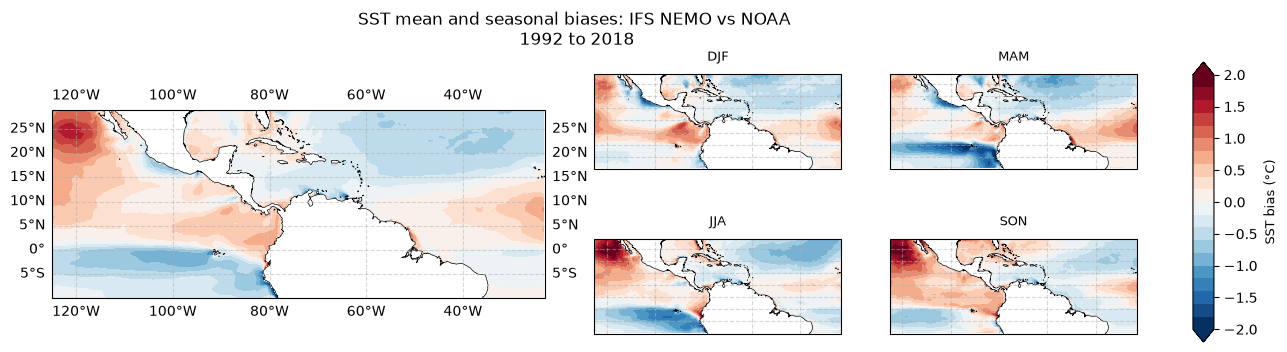

In [12]:
projection = ccrs.PlateCarree()
fsize = 8

exp_ref = "noaa_tos"
exp_model = "nemo_tos"

# --- Set up figure and GridSpec ---
# 2 rows x 3 cols: left col (wide) spans both rows, right 2x2 grid in cols 1-2
fig = plt.figure(figsize=(14, 4))

gs = gridspec.GridSpec(
    2, 3,
    width_ratios=[2, 1, 1],   # left column twice as wide as each right column
    wspace=0.15, hspace=0.15,
    figure=fig
)

cmap = plt.get_cmap("RdBu_r")
cbar_min, cbar_max = -2, 2  # adjust to your bias range
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

# --- Left panel: overall mean bias ---
ax_map = fig.add_subplot(gs[:, 0], projection=projection)

mean_bias = globals()[f"{exp_model}_mean"] - globals()[f"{exp_ref}_mean"]  # adjust to however your mean field is named

longitude = mean_bias.lon.values
latitude = mean_bias.lat.values

lons, lats = np.meshgrid(longitude, latitude)

pcm = ax_map.pcolormesh(
    lons, lats, mean_bias, transform=projection, cmap=cmap,
    shading='auto', vmin=cbar_min, vmax=cbar_max
)

ax_map.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)

gl = ax_map.gridlines(draw_labels=True, linestyle='dashed', alpha=0.5)
# gl.top_labels = False
# gl.left_labels = True
# gl.bottom_labels = True
# gl.right_labels = False
# gl.xlabel_style = {'size': fsize, 'rotation': 45}
# gl.ylabel_style = {'size': fsize}
# ax_map.set_title("Annual mean SST bias", fontsize=fsize + 2)


# --- Right panels: seasonal biases in 2x2 grid ---
# positions within the 2x2 block: row, col in {0,1} x {1,2}
positions = [(0, 1), (0, 2), (1, 1), (1, 2)]

for season, (row, col) in zip(seasons, positions):
    ax = fig.add_subplot(gs[row, col], projection=projection)

    to_plot = globals()[f"{exp_model}_{season}"] - globals()[f"{exp_ref}_{season}"]

    pcm_season = ax.pcolormesh(
        lons, lats, to_plot, transform=projection, cmap=cmap,
        shading='auto', vmin=cbar_min, vmax=cbar_max
    )

    ax.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
    #ax.set_aspect('auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    gl = ax.gridlines(draw_labels=False, linestyle='dashed', alpha=0.5)

    ax.set_title(season, fontsize=fsize + 1, pad=10)
    # gl.xlabel_style = {'size': fsize, 'rotation': 45}
    # gl.ylabel_style = {'size': fsize}

# --- Shared colorbar ---
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(pcm, cax=cbar_ax, extend='both')
cbar.set_label("SST bias (°C)", fontsize=fsize + 1)

fig.suptitle("SST mean and seasonal biases: IFS NEMO vs NOAA " \
f"\n{start_time} to {end_time}", fontsize=fsize + 4)
plt.show()

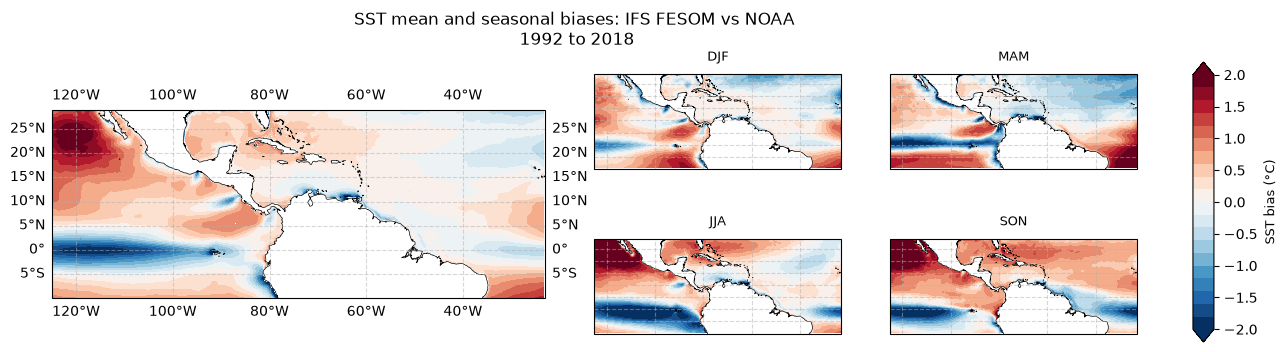

In [13]:
projection = ccrs.PlateCarree()
fsize = 8

exp_ref = "noaa_tos"
exp_model = "fesom_tos"

# --- Set up figure and GridSpec ---
# 2 rows x 3 cols: left col (wide) spans both rows, right 2x2 grid in cols 1-2
fig = plt.figure(figsize=(14, 4))

gs = gridspec.GridSpec(
    2, 3,
    width_ratios=[2, 1, 1],   # left column twice as wide as each right column
    wspace=0.15, hspace=0.15,
    figure=fig
)

cmap = plt.get_cmap("RdBu_r")
cbar_min, cbar_max = -2, 2  # adjust to your bias range
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

# --- Left panel: overall mean bias ---
ax_map = fig.add_subplot(gs[:, 0], projection=projection)

mean_bias = globals()[f"{exp_model}_mean"] - globals()[f"{exp_ref}_mean"]  # adjust to however your mean field is named

longitude = mean_bias.lon.values
latitude = mean_bias.lat.values

lons, lats = np.meshgrid(longitude, latitude)

pcm = ax_map.pcolormesh(
    lons, lats, mean_bias, transform=projection, cmap=cmap,
    shading='auto', vmin=cbar_min, vmax=cbar_max
)

ax_map.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)

gl = ax_map.gridlines(draw_labels=True, linestyle='dashed', alpha=0.5)
# gl.top_labels = False
# gl.left_labels = True
# gl.bottom_labels = True
# gl.right_labels = False
# gl.xlabel_style = {'size': fsize, 'rotation': 45}
# gl.ylabel_style = {'size': fsize}
# ax_map.set_title("Annual mean SST bias", fontsize=fsize + 2)


# --- Right panels: seasonal biases in 2x2 grid ---
# positions within the 2x2 block: row, col in {0,1} x {1,2}
positions = [(0, 1), (0, 2), (1, 1), (1, 2)]

for season, (row, col) in zip(seasons, positions):
    ax = fig.add_subplot(gs[row, col], projection=projection)

    to_plot = globals()[f"{exp_model}_{season}"] - globals()[f"{exp_ref}_{season}"]

    pcm_season = ax.pcolormesh(
        lons, lats, to_plot, transform=projection, cmap=cmap,
        shading='auto', vmin=cbar_min, vmax=cbar_max
    )

    ax.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
    #ax.set_aspect('auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    gl = ax.gridlines(draw_labels=False, linestyle='dashed', alpha=0.5)

    ax.set_title(season, fontsize=fsize + 1, pad=10)
    # gl.xlabel_style = {'size': fsize, 'rotation': 45}
    # gl.ylabel_style = {'size': fsize}

# --- Shared colorbar ---
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(pcm, cax=cbar_ax, extend='both')
cbar.set_label("SST bias (°C)", fontsize=fsize + 1)

fig.suptitle("SST mean and seasonal biases: IFS FESOM vs NOAA " \
f"\n{start_time} to {end_time}", fontsize=fsize + 4)
plt.show()

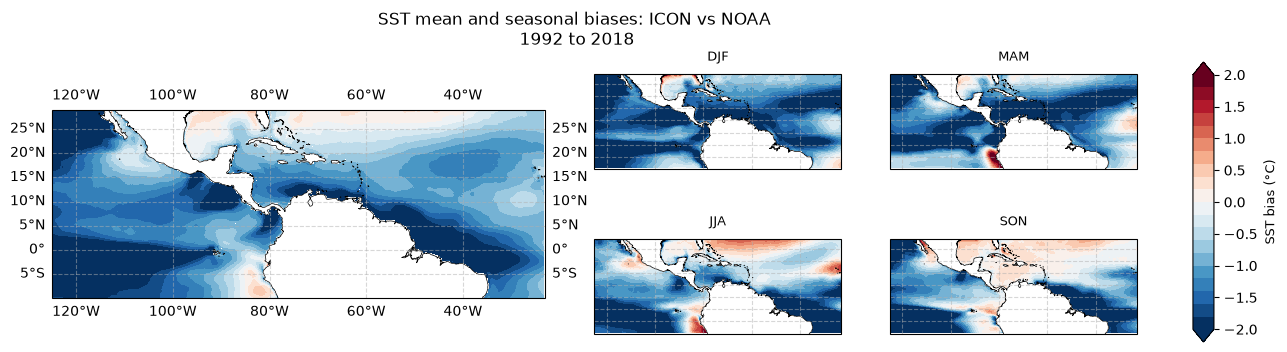

In [14]:
projection = ccrs.PlateCarree()
fsize = 8

exp_ref = "noaa_tos"
exp_model = "icon_tos"

# --- Set up figure and GridSpec ---
# 2 rows x 3 cols: left col (wide) spans both rows, right 2x2 grid in cols 1-2
fig = plt.figure(figsize=(14, 4))

gs = gridspec.GridSpec(
    2, 3,
    width_ratios=[2, 1, 1],   # left column twice as wide as each right column
    wspace=0.15, hspace=0.15,
    figure=fig
)

cmap = plt.get_cmap("RdBu_r")
cbar_min, cbar_max = -2, 2  # adjust to your bias range
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

# --- Left panel: overall mean bias ---
ax_map = fig.add_subplot(gs[:, 0], projection=projection)

mean_bias = globals()[f"{exp_model}_mean"] - globals()[f"{exp_ref}_mean"]  # adjust to however your mean field is named

longitude = mean_bias.lon.values
latitude = mean_bias.lat.values

lons, lats = np.meshgrid(longitude, latitude)

pcm = ax_map.pcolormesh(
    lons, lats, mean_bias, transform=projection, cmap=cmap,
    shading='auto', vmin=cbar_min, vmax=cbar_max
)

ax_map.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)

gl = ax_map.gridlines(draw_labels=True, linestyle='dashed', alpha=0.5)
# gl.top_labels = False
# gl.left_labels = True
# gl.bottom_labels = True
# gl.right_labels = False
# gl.xlabel_style = {'size': fsize, 'rotation': 45}
# gl.ylabel_style = {'size': fsize}
# ax_map.set_title("Annual mean SST bias", fontsize=fsize + 2)


# --- Right panels: seasonal biases in 2x2 grid ---
# positions within the 2x2 block: row, col in {0,1} x {1,2}
positions = [(0, 1), (0, 2), (1, 1), (1, 2)]

for season, (row, col) in zip(seasons, positions):
    ax = fig.add_subplot(gs[row, col], projection=projection)

    to_plot = globals()[f"{exp_model}_{season}"] - globals()[f"{exp_ref}_{season}"]

    pcm_season = ax.pcolormesh(
        lons, lats, to_plot, transform=projection, cmap=cmap,
        shading='auto', vmin=cbar_min, vmax=cbar_max
    )

    ax.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
    #ax.set_aspect('auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    gl = ax.gridlines(draw_labels=False, linestyle='dashed', alpha=0.5)

    ax.set_title(season, fontsize=fsize + 1, pad=10)
    # gl.xlabel_style = {'size': fsize, 'rotation': 45}
    # gl.ylabel_style = {'size': fsize}

# --- Shared colorbar ---
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(pcm, cax=cbar_ax, extend='both')
cbar.set_label("SST bias (°C)", fontsize=fsize + 1)

fig.suptitle("SST mean and seasonal biases: ICON vs NOAA " \
f"\n{start_time} to {end_time}", fontsize=fsize + 4)
plt.show()

# Comparision against ESA high res monthly means

In [16]:
# create mean values and also seasonal averages

# THE REGRIDDING IS VERY SLOW, CAN YOU SPEED UP? 

start_time = "1992"
end_time = "2019"

exps = ["esa_tos", "nemo_tos", "fesom_tos", "icon_tos"]
seasons = ["DJF", "MAM", "JJA", "SON"]

method = "nearest_s2d" # faster re-gridding for now
for exp in exps:

    print(exp)
    time_slice = globals()[f"{exp}"].sel(time = slice(start_time, end_time))
    globals()[f"{exp}_mean"] = time_slice.mean(dim = "time")

    if exp in ["nemo_tos", "fesom_tos", "icon_tos"]:
        # also re-grid the CliamteDT (0.1 from regridding) to the grid of the obs (0.05)
        globals()[f"{exp}_mean"] = matching_resolutions_xe(globals()[f"{exp}_mean"], 
                                                           globals()["esa_tos_mean"], 
                                                           method
                                                        )

    season_slice = time_slice.groupby("time.season")
    for season in seasons:
        globals()[f"{exp}_{season}"] = season_slice[f"{season}"].mean(dim = "time")

        if exp in ["nemo_tos", "fesom_tos", "icon_tos"]:
            globals()[f"{exp}_{season}"] = matching_resolutions_xe(globals()[f"{exp}_{season}"], 
                                                                   globals()[f"esa_tos_{season}"],
                                                                   method
                                                                )


esa_tos


nemo_tos
fesom_tos
icon_tos


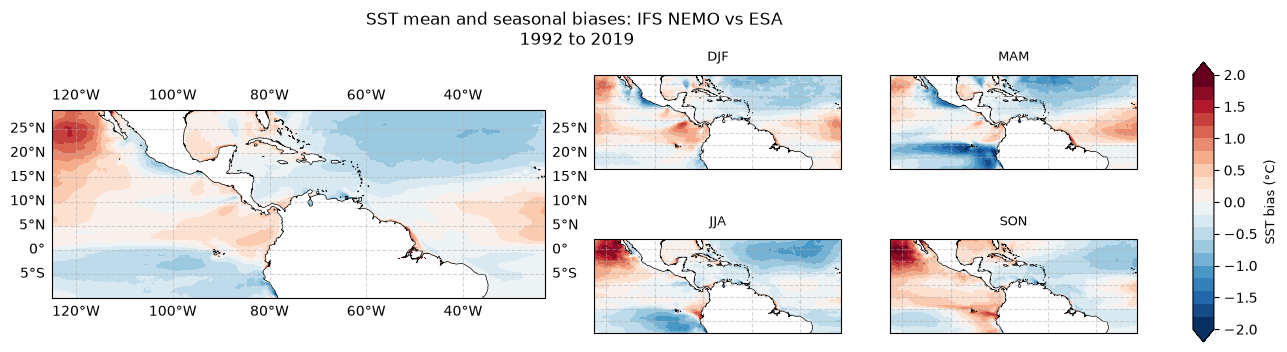

In [17]:


projection = ccrs.PlateCarree()
fsize = 8

exp_ref = "esa_tos"
exp_model = "nemo_tos"

# --- Set up figure and GridSpec ---
# 2 rows x 3 cols: left col (wide) spans both rows, right 2x2 grid in cols 1-2
fig = plt.figure(figsize=(14, 4))

gs = gridspec.GridSpec(
    2, 3,
    width_ratios=[2, 1, 1],   # left column twice as wide as each right column
    wspace=0.15, hspace=0.15,
    figure=fig
)

cmap = plt.get_cmap("RdBu_r")
cbar_min, cbar_max = -2, 2  # adjust to your bias range
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

# --- Left panel: overall mean bias ---
ax_map = fig.add_subplot(gs[:, 0], projection=projection)

mean_bias = globals()[f"{exp_model}_mean"] - globals()[f"{exp_ref}_mean"]  # adjust to however your mean field is named

longitude = mean_bias.lon.values
latitude = mean_bias.lat.values

lons, lats = np.meshgrid(longitude, latitude)

pcm = ax_map.pcolormesh(
    lons, lats, mean_bias, transform=projection, cmap=cmap,
    shading='auto', vmin=cbar_min, vmax=cbar_max
)

ax_map.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)

gl = ax_map.gridlines(draw_labels=True, linestyle='dashed', alpha=0.5)
# gl.top_labels = False
# gl.left_labels = True
# gl.bottom_labels = True
# gl.right_labels = False
# gl.xlabel_style = {'size': fsize, 'rotation': 45}
# gl.ylabel_style = {'size': fsize}
# ax_map.set_title("Annual mean SST bias", fontsize=fsize + 2)


# --- Right panels: seasonal biases in 2x2 grid ---
# positions within the 2x2 block: row, col in {0,1} x {1,2}
positions = [(0, 1), (0, 2), (1, 1), (1, 2)]

for season, (row, col) in zip(seasons, positions):
    ax = fig.add_subplot(gs[row, col], projection=projection)

    to_plot = globals()[f"{exp_model}_{season}"] - globals()[f"{exp_ref}_{season}"]

    pcm_season = ax.pcolormesh(
        lons, lats, to_plot, transform=projection, cmap=cmap,
        shading='auto', vmin=cbar_min, vmax=cbar_max
    )

    ax.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
    #ax.set_aspect('auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    gl = ax.gridlines(draw_labels=False, linestyle='dashed', alpha=0.5)

    ax.set_title(season, fontsize=fsize + 1, pad=10)
    # gl.xlabel_style = {'size': fsize, 'rotation': 45}
    # gl.ylabel_style = {'size': fsize}

# --- Shared colorbar ---
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(pcm, cax=cbar_ax, extend='both')
cbar.set_label("SST bias (°C)", fontsize=fsize + 1)

fig.suptitle("SST mean and seasonal biases: IFS NEMO vs ESA " \
f"\n{start_time} to {end_time}", fontsize=fsize + 4)
plt.show()

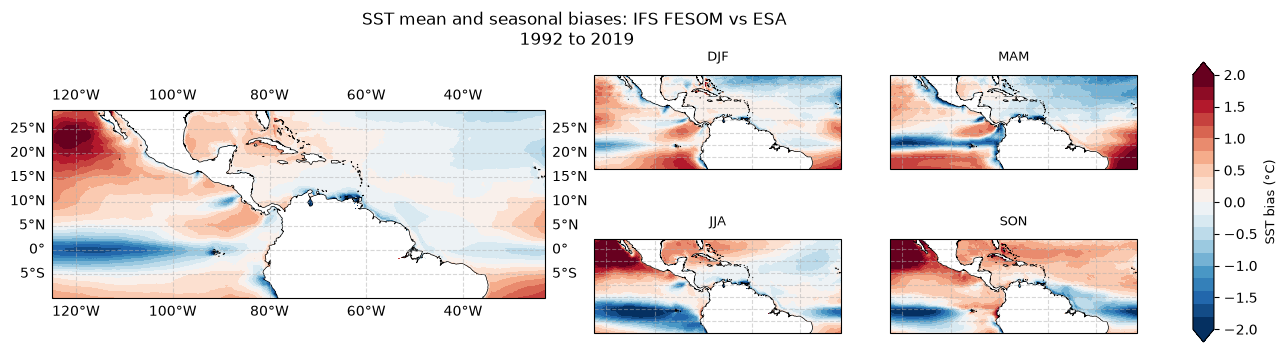

In [18]:


projection = ccrs.PlateCarree()
fsize = 8

exp_ref = "esa_tos"
exp_model = "fesom_tos"

# --- Set up figure and GridSpec ---
# 2 rows x 3 cols: left col (wide) spans both rows, right 2x2 grid in cols 1-2
fig = plt.figure(figsize=(14, 4))

gs = gridspec.GridSpec(
    2, 3,
    width_ratios=[2, 1, 1],   # left column twice as wide as each right column
    wspace=0.15, hspace=0.15,
    figure=fig
)

cmap = plt.get_cmap("RdBu_r")
cbar_min, cbar_max = -2, 2  # adjust to your bias range
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

# --- Left panel: overall mean bias ---
ax_map = fig.add_subplot(gs[:, 0], projection=projection)

mean_bias = globals()[f"{exp_model}_mean"] - globals()[f"{exp_ref}_mean"]  # adjust to however your mean field is named

longitude = mean_bias.lon.values
latitude = mean_bias.lat.values

lons, lats = np.meshgrid(longitude, latitude)

pcm = ax_map.pcolormesh(
    lons, lats, mean_bias, transform=projection, cmap=cmap,
    shading='auto', vmin=cbar_min, vmax=cbar_max
)

ax_map.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)

gl = ax_map.gridlines(draw_labels=True, linestyle='dashed', alpha=0.5)
# gl.top_labels = False
# gl.left_labels = True
# gl.bottom_labels = True
# gl.right_labels = False
# gl.xlabel_style = {'size': fsize, 'rotation': 45}
# gl.ylabel_style = {'size': fsize}
# ax_map.set_title("Annual mean SST bias", fontsize=fsize + 2)


# --- Right panels: seasonal biases in 2x2 grid ---
# positions within the 2x2 block: row, col in {0,1} x {1,2}
positions = [(0, 1), (0, 2), (1, 1), (1, 2)]

for season, (row, col) in zip(seasons, positions):
    ax = fig.add_subplot(gs[row, col], projection=projection)

    to_plot = globals()[f"{exp_model}_{season}"] - globals()[f"{exp_ref}_{season}"]

    pcm_season = ax.pcolormesh(
        lons, lats, to_plot, transform=projection, cmap=cmap,
        shading='auto', vmin=cbar_min, vmax=cbar_max
    )

    ax.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
    #ax.set_aspect('auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    gl = ax.gridlines(draw_labels=False, linestyle='dashed', alpha=0.5)

    ax.set_title(season, fontsize=fsize + 1, pad=10)
    # gl.xlabel_style = {'size': fsize, 'rotation': 45}
    # gl.ylabel_style = {'size': fsize}

# --- Shared colorbar ---
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(pcm, cax=cbar_ax, extend='both')
cbar.set_label("SST bias (°C)", fontsize=fsize + 1)

fig.suptitle("SST mean and seasonal biases: IFS FESOM vs ESA " \
f"\n{start_time} to {end_time}", fontsize=fsize + 4)
plt.show()

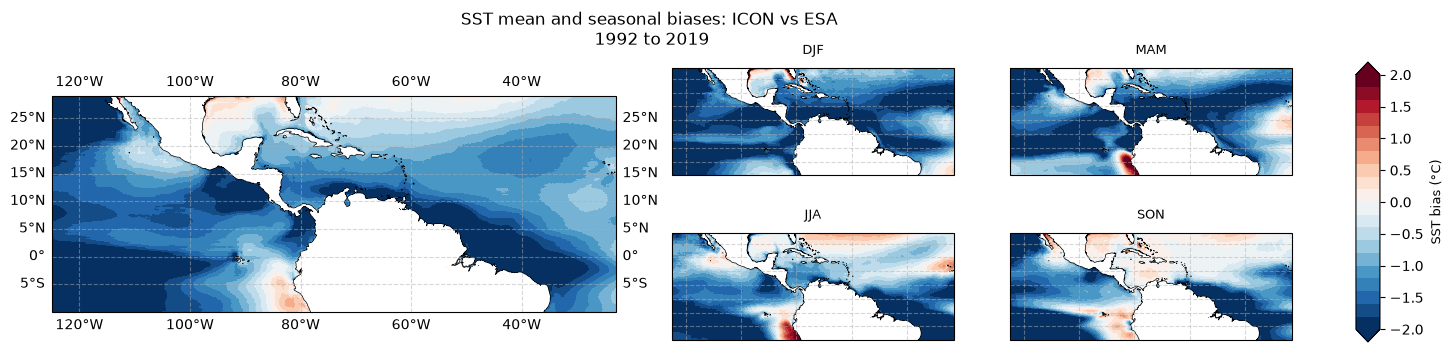

In [19]:
projection = ccrs.PlateCarree()
fsize = 8

exp_ref = "esa_tos"
exp_model = "icon_tos"

# --- Set up figure and GridSpec ---
# 2 rows x 3 cols: left col (wide) spans both rows, right 2x2 grid in cols 1-2
fig = plt.figure(figsize=(16, 4))

gs = gridspec.GridSpec(
    2, 3,
    width_ratios=[2, 1, 1],   # left column twice as wide as each right column
    wspace=0.15, hspace=0.15,
    figure=fig
)

cmap = plt.get_cmap("RdBu_r")
cbar_min, cbar_max = -2, 2  # adjust to your bias range
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

# --- Left panel: overall mean bias ---
ax_map = fig.add_subplot(gs[:, 0], projection=projection)

mean_bias = globals()[f"{exp_model}_mean"] - globals()[f"{exp_ref}_mean"]  # adjust to however your mean field is named

longitude = mean_bias.lon.values
latitude = mean_bias.lat.values

lons, lats = np.meshgrid(longitude, latitude)

pcm = ax_map.pcolormesh(
    lons, lats, mean_bias, transform=projection, cmap=cmap,
    shading='auto', vmin=cbar_min, vmax=cbar_max
)

ax_map.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)

gl = ax_map.gridlines(draw_labels=True, linestyle='dashed', alpha=0.5)
# gl.top_labels = False
# gl.left_labels = True
# gl.bottom_labels = True
# gl.right_labels = False
# gl.xlabel_style = {'size': fsize, 'rotation': 45}
# gl.ylabel_style = {'size': fsize}
# ax_map.set_title("Annual mean SST bias", fontsize=fsize + 2)


# --- Right panels: seasonal biases in 2x2 grid ---
# positions within the 2x2 block: row, col in {0,1} x {1,2}
positions = [(0, 1), (0, 2), (1, 1), (1, 2)]

for season, (row, col) in zip(seasons, positions):
    ax = fig.add_subplot(gs[row, col], projection=projection)

    to_plot = globals()[f"{exp_model}_{season}"] - globals()[f"{exp_ref}_{season}"]

    pcm_season = ax.pcolormesh(
        lons, lats, to_plot, transform=projection, cmap=cmap,
        shading='auto', vmin=cbar_min, vmax=cbar_max
    )

    ax.set_extent([longitude[0], longitude[-1], latitude[0], latitude[-1]], crs=projection)
    #ax.set_aspect('auto')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    gl = ax.gridlines(draw_labels=False, linestyle='dashed', alpha=0.5)

    ax.set_title(season, fontsize=fsize + 1, pad=10)
    # gl.xlabel_style = {'size': fsize, 'rotation': 45}
    # gl.ylabel_style = {'size': fsize}

# --- Shared colorbar ---
cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
cbar = fig.colorbar(pcm, cax=cbar_ax, extend='both')
cbar.set_label("SST bias (°C)", fontsize=fsize + 1)

fig.suptitle("SST mean and seasonal biases: ICON vs ESA " \
f"\n{start_time} to {end_time}", fontsize=fsize + 4)
plt.show()

In [ ]:
globals()[f"{exp}"].lat[-1].values

IndexError: too many indices for array: array is 0-dimensional, but 1 were indexed

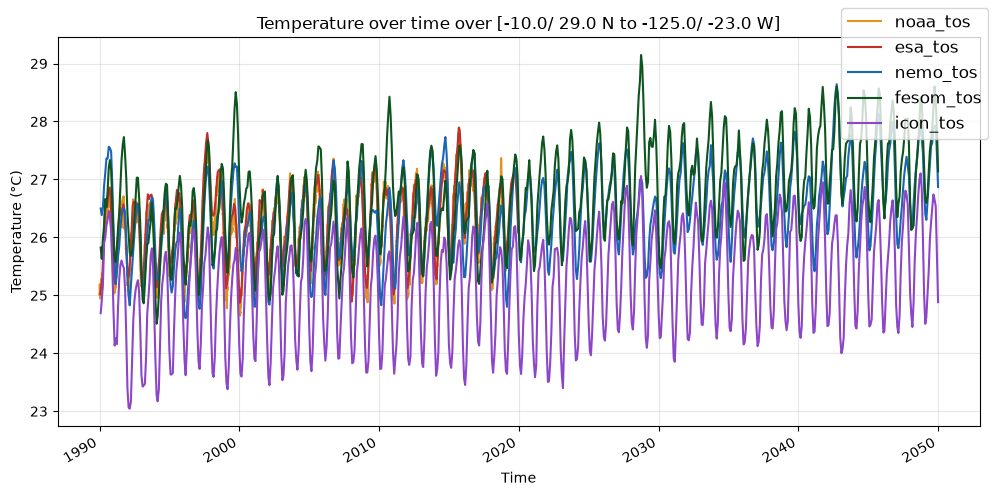

In [37]:
# let's plot a simple x-y with temp over time 
fs = 12

exps = ["noaa_tos", "esa_tos", "nemo_tos", "fesom_tos", "icon_tos"]

colors = [ "#e2931d", "#c02f2a", "#1a65b4", "#0d551e",  "#8d46c7"] # sns.dark_palette("xkcd:golden", 8)

fig, ax = plt.subplots(figsize=(10, 5))

for index, exp in enumerate(exps):
    to_plot = globals()[f"{exp}"].mean(dim = ["lat", "lon"])
    ax.plot(to_plot.time, to_plot,  
            color=colors[index],
            label = exp,
            linewidth=1.5)

ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature over time over ["\
             f"{globals()[f"{exp}"].lat[-1].values}/ "\
             f"{globals()[f"{exp}"].lat[0].values} N to "\
             f"{globals()[f"{exp}"].lon[0].values}/ "\
             f"{globals()[f"{exp}"].lon[-1].values} W]")

fig.legend(fontsize = fs)

ax.grid(alpha=0.3)
fig.autofmt_xdate()  # rotates date labels for readability

plt.tight_layout()
plt.show()

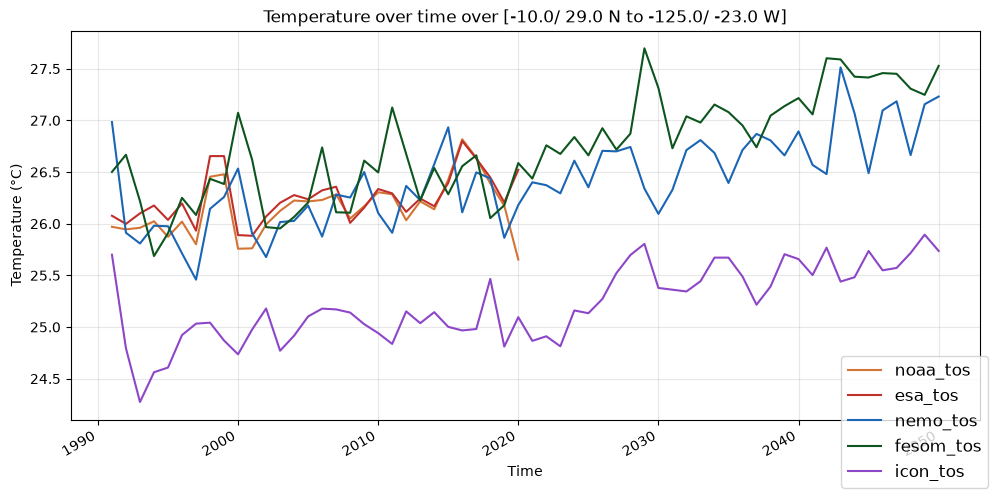

In [38]:
# let's plot a simple x-y with temp over time 
fs = 12

exps = ["noaa_tos", "esa_tos", "nemo_tos", "fesom_tos", "icon_tos"]

colors = ["#d47434", "#c02f2a", "#1a65b4", "#0d551e",  "#8d46c7"] # sns.dark_palette("xkcd:golden", 8)

fig, ax = plt.subplots(figsize=(10, 5))

for index, exp in enumerate(exps):
    to_plot = globals()[f"{exp}"].mean(dim = ["lat", "lon"])
    to_plot = to_plot.resample(time = "YE").mean()
    ax.plot(to_plot.time, to_plot,  
            color=colors[index],
            label = exp,
            linewidth=1.5)

ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature over time over ["\
             f"{globals()[f"{exp}"].lat[-1].values}/ "\
             f"{globals()[f"{exp}"].lat[0].values} N to "\
             f"{globals()[f"{exp}"].lon[0].values}/ "\
             f"{globals()[f"{exp}"].lon[-1].values} W]")

fig.legend(fontsize = fs, loc = "lower right")

ax.grid(alpha=0.3)
fig.autofmt_xdate()  # rotates date labels for readability

plt.tight_layout()
plt.show()

# re-calculating mean bias for islands 